In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("../dataset/PS_20174392719_1491204439457_log.csv")

df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [3]:
df.shape

(6362620, 11)

In [4]:
df.columns

Index(['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig',
       'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud',
       'isFlaggedFraud'],
      dtype='str')

In [7]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [9]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [10]:
df['isFraud'].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

Matplotlib is building the font cache; this may take a moment.


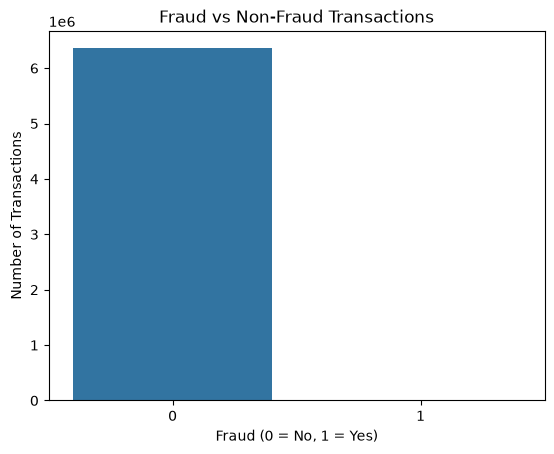

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='isFraud', data=df)

plt.title('Fraud vs Non-Fraud Transactions')
plt.xlabel('Fraud (0 = No, 1 = Yes)')
plt.ylabel('Number of Transactions')
plt.show()

In [12]:
df['type'].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [13]:
pd.crosstab(df['type'], df['isFraud'])

isFraud,0,1
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


In [14]:
fraud_rate = df.groupby('type')['isFraud'].mean() * 100

fraud_rate

type
CASH_IN     0.000000
CASH_OUT    0.183955
DEBIT       0.000000
PAYMENT     0.000000
TRANSFER    0.768799
Name: isFraud, dtype: float64

In [15]:
df['amount'].describe()

count    6.362620e+06
mean     1.798619e+05
std      6.038582e+05
min      0.000000e+00
25%      1.338957e+04
50%      7.487194e+04
75%      2.087215e+05
max      9.244552e+07
Name: amount, dtype: float64

In [16]:
df.groupby('isFraud')['amount'].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


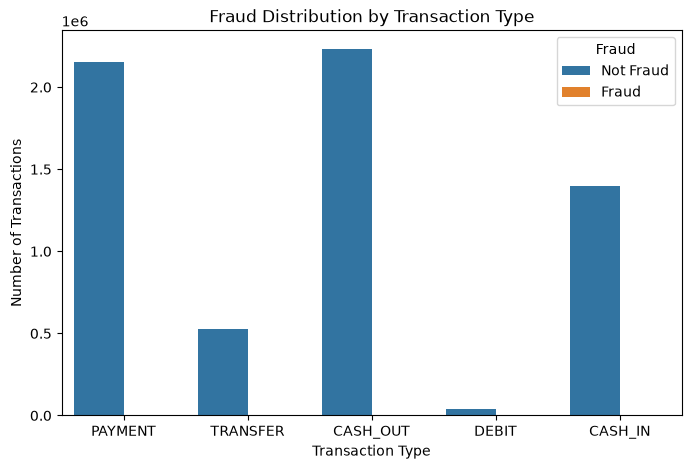

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='type', hue='isFraud')

plt.title('Fraud Distribution by Transaction Type')
plt.xlabel('Transaction Type')
plt.ylabel('Number of Transactions')
plt.legend(title='Fraud', labels=['Not Fraud', 'Fraud'])
plt.show()

In [18]:
df.duplicated().sum()

np.int64(0)

In [19]:
df['isFraud'].value_counts(normalize=True) * 100

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64

In [20]:
df.groupby('type')['amount'].agg(['count', 'mean', 'median', 'max'])

,count,mean,median,max
type,,,,
CASH_IN,1399284,168920.242004,143427.710,1915267.90
CASH_OUT,2237500,176273.964346,147072.185,10000000.00
DEBIT,41432,5483.665314,3048.990,569077.51
PAYMENT,2151495,13057.604660,9482.190,238637.98
TRANSFER,532909,910647.009645,486308.390,92445516.64


In [21]:
df['balance_diff_orig'] = df['oldbalanceOrg'] - df['newbalanceOrig']

df[['amount', 'oldbalanceOrg', 'newbalanceOrig', 'balance_diff_orig']].head()

,amount,oldbalanceOrg,newbalanceOrig,balance_diff_orig
0,9839.64,170136.0,160296.36,9839.64
1,1864.28,21249.0,19384.72,1864.28
2,181.00,181.0,0.00,181.00
3,181.00,181.0,0.00,181.00
4,11668.14,41554.0,29885.86,11668.14


In [22]:
df['balance_diff_dest'] = df['newbalanceDest'] - df['oldbalanceDest']

df[['amount', 'oldbalanceDest', 'newbalanceDest', 'balance_diff_dest']].head()

,amount,oldbalanceDest,newbalanceDest,balance_diff_dest
0,9839.64,0.0,0.0,0.0
1,1864.28,0.0,0.0,0.0
2,181.00,0.0,0.0,0.0
3,181.00,21182.0,0.0,-21182.0
4,11668.14,0.0,0.0,0.0


In [23]:
df.groupby('isFraud')[['amount', 'balance_diff_orig', 'balance_diff_dest']].mean()

,amount,balance_diff_orig,balance_diff_dest
isFraud,,,
0,1.781970e+05,-2.314152e+04,123504.809994
1,1.467967e+06,1.457275e+06,735457.998071


In [24]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud,balance_diff_orig,balance_diff_dest
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0,9839.64,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0,1864.28,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0,181.00,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0,181.00,-21182.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0,11668.14,0.0


In [25]:
features = [
    'step',
    'type',
    'amount',
    'oldbalanceOrg',
    'newbalanceOrig',
    'oldbalanceDest',
    'newbalanceDest',
    'isFlaggedFraud',
    'balance_diff_orig',
    'balance_diff_dest'
]

X = df[features]
y = df['isFraud']

X.head()

,step,type,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFlaggedFraud,balance_diff_orig,balance_diff_dest
0,1,PAYMENT,9839.64,170136.0,160296.36,0.0,0.0,0,9839.64,0.0
1,1,PAYMENT,1864.28,21249.0,19384.72,0.0,0.0,0,1864.28,0.0
2,1,TRANSFER,181.00,181.0,0.00,0.0,0.0,0,181.00,0.0
3,1,CASH_OUT,181.00,181.0,0.00,21182.0,0.0,0,181.00,-21182.0
4,1,PAYMENT,11668.14,41554.0,29885.86,0.0,0.0,0,11668.14,0.0


In [26]:
X = pd.get_dummies(X, columns=['type'], drop_first=True)

X.head()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFlaggedFraud,balance_diff_orig,balance_diff_dest,type_CASH_OUT,type_DEBIT,type_PAYMENT,type_TRANSFER
0,1,9839.64,170136.0,160296.36,0.0,0.0,0,9839.64,0.0,False,False,True,False
1,1,1864.28,21249.0,19384.72,0.0,0.0,0,1864.28,0.0,False,False,True,False
2,1,181.00,181.0,0.00,0.0,0.0,0,181.00,0.0,False,False,False,True
3,1,181.00,181.0,0.00,21182.0,0.0,0,181.00,-21182.0,True,False,False,False
4,1,11668.14,41554.0,29885.86,0.0,0.0,0,11668.14,0.0,False,False,True,False


In [27]:
X.columns

Index(['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest',
       'newbalanceDest', 'isFlaggedFraud', 'balance_diff_orig',
       'balance_diff_dest', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT',
       'type_TRANSFER'],
      dtype='str')

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 5090096
Testing samples: 1272524


In [29]:
print("Training:")
print(y_train.value_counts())

print("\nTesting:")
print(y_test.value_counts())

Training:
isFraud
0    5083526
1       6570
Name: count, dtype: int64

Testing:
isFraud
0    1270881
1       1643
Name: count, dtype: int64


In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed")

Scaling completed


In [31]:
from sklearn.linear_model import LogisticRegression

model_lr = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

model_lr.fit(X_train_scaled, y_train)

print("Logistic Regression training completed")

Logistic Regression training completed


In [32]:
y_pred_lr = model_lr.predict(X_test_scaled)

print("Predictions completed")

Predictions completed


In [33]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, y_pred_lr))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       1.00      0.95      0.98   1270881
           1       0.03      0.98      0.05      1643

    accuracy                           0.95   1272524
   macro avg       0.51      0.97      0.51   1272524
weighted avg       1.00      0.95      0.97   1272524

Confusion Matrix:
[[1209783   61098]
 [     32    1611]]


In [34]:
from sklearn.metrics import roc_auc_score

y_prob_lr = model_lr.predict_proba(X_test_scaled)[:, 1]

roc_auc_lr = roc_auc_score(y_test, y_prob_lr)

print("Logistic Regression ROC-AUC:", roc_auc_lr)

Logistic Regression ROC-AUC: 0.9949073600288427


In [35]:
from sklearn.ensemble import RandomForestClassifier

model_rf = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

model_rf.fit(X_train, y_train)

print("Random Forest training completed")

Random Forest training completed


In [36]:
y_pred_rf = model_rf.predict(X_test)

print("Random Forest predictions completed")

Random Forest predictions completed


In [37]:
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_test, y_pred_rf))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00   1270881
           1       0.91      0.88      0.90      1643

    accuracy                           1.00   1272524
   macro avg       0.96      0.94      0.95   1272524
weighted avg       1.00      1.00      1.00   1272524

Confusion Matrix:
[[1270744     137]
 [    198    1445]]


In [38]:
y_prob_rf = model_rf.predict_proba(X_test)[:, 1]

roc_auc_rf = roc_auc_score(y_test, y_prob_rf)

print("Random Forest ROC-AUC:", roc_auc_rf)

Random Forest ROC-AUC: 0.9977941349615613


In [39]:
feature_importance = pd.Series(
    model_rf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

feature_importance

balance_diff_orig    0.350093
oldbalanceOrg        0.155203
amount               0.108707
newbalanceOrig       0.103536
balance_diff_dest    0.068761
type_TRANSFER        0.055084
type_PAYMENT         0.040136
step                 0.037216
newbalanceDest       0.029295
type_CASH_OUT        0.027283
oldbalanceDest       0.023223
isFlaggedFraud       0.001063
type_DEBIT           0.000401
dtype: float64

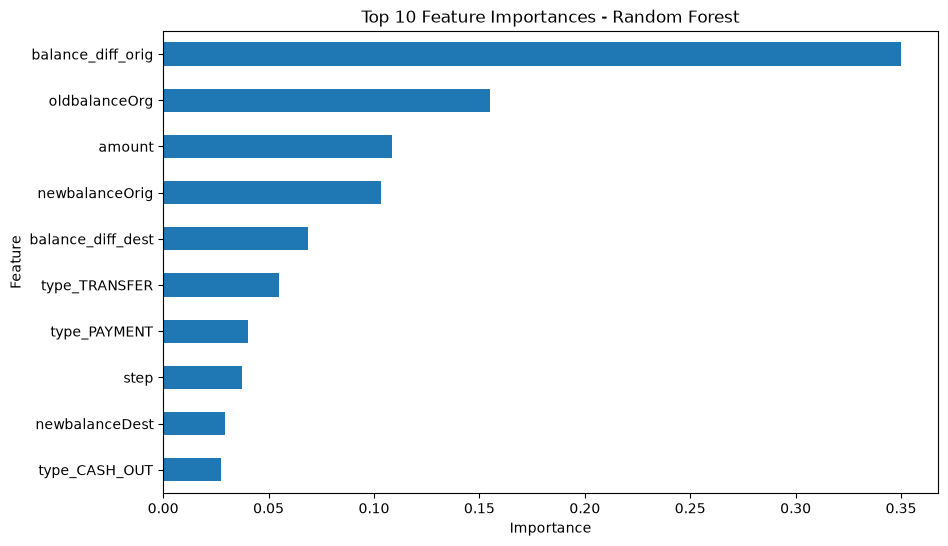

In [40]:
plt.figure(figsize=(10, 6))

feature_importance.head(10).sort_values().plot(kind='barh')

plt.title('Top 10 Feature Importances - Random Forest')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.show()

In [41]:
import joblib

joblib.dump(model_rf, "fraud_detection_model.pkl")

print("Model saved successfully")

Model saved successfully


In [42]:
joblib.dump(X.columns.tolist(), "feature_columns.pkl")

print("Feature columns saved successfully")

Feature columns saved successfully


In [1]:
import joblib

model = joblib.load("../models/fraud_detection_model.pkl")
feature_columns = joblib.load("../models/feature_columns.pkl")

print("Model loaded successfully!")
print("Number of features:", len(feature_columns))
print("Features:", feature_columns)

Model loaded successfully!
Number of features: 13
Features: ['step', 'amount', 'oldbalanceOrg', 'newbalanceOrig', 'oldbalanceDest', 'newbalanceDest', 'isFlaggedFraud', 'balance_diff_orig', 'balance_diff_dest', 'type_CASH_OUT', 'type_DEBIT', 'type_PAYMENT', 'type_TRANSFER']


In [3]:
def predict_fraud(step, transaction_type, amount,
                  oldbalanceOrg, newbalanceOrig,
                  oldbalanceDest, newbalanceDest,
                  isFlaggedFraud):

    # Create input data
    input_data = pd.DataFrame({
        "step": [step],
        "amount": [amount],
        "oldbalanceOrg": [oldbalanceOrg],
        "newbalanceOrig": [newbalanceOrig],
        "oldbalanceDest": [oldbalanceDest],
        "newbalanceDest": [newbalanceDest],
        "isFlaggedFraud": [isFlaggedFraud]
    })

    # Create balance difference features
    input_data["balance_diff_orig"] = (
        input_data["oldbalanceOrg"] - input_data["newbalanceOrig"]
    )

    input_data["balance_diff_dest"] = (
        input_data["newbalanceDest"] - input_data["oldbalanceDest"]
    )

    # One-hot encode transaction type
    input_data["type_CASH_OUT"] = transaction_type == "CASH_OUT"
    input_data["type_DEBIT"] = transaction_type == "DEBIT"
    input_data["type_PAYMENT"] = transaction_type == "PAYMENT"
    input_data["type_TRANSFER"] = transaction_type == "TRANSFER"

    # Arrange columns exactly as during training
    input_data = input_data[feature_columns]

    # Prediction
    prediction = model.predict(input_data)[0]

    if prediction == 1:
        return "Fraud"
    else:
        return "Not Fraud"

In [4]:
result = predict_fraud(
    step=1,
    transaction_type="TRANSFER",
    amount=1000000,
    oldbalanceOrg=1000000,
    newbalanceOrig=0,
    oldbalanceDest=0,
    newbalanceDest=0,
    isFlaggedFraud=0
)

print("Prediction:", result)

NameError: name 'pd' is not defined

In [5]:
def predict_fraud(step, transaction_type, amount,
                  oldbalanceOrg, newbalanceOrig,
                  oldbalanceDest, newbalanceDest,
                  isFlaggedFraud):

SyntaxError: incomplete input (3622432917.py, line 4)

In [7]:
def predict_fraud(step, transaction_type, amount,
                  oldbalanceOrg, newbalanceOrig,
                  oldbalanceDest, newbalanceDest,
                  isFlaggedFraud):

    input_data = pd.DataFrame({
        "step": [step],
        "amount": [amount],
        "oldbalanceOrg": [oldbalanceOrg],
        "newbalanceOrig": [newbalanceOrig],
        "oldbalanceDest": [oldbalanceDest],
        "newbalanceDest": [newbalanceDest],
        "isFlaggedFraud": [isFlaggedFraud]
    })

    input_data["balance_diff_orig"] = (
        input_data["oldbalanceOrg"] - input_data["newbalanceOrig"]
    )

    input_data["balance_diff_dest"] = (
        input_data["newbalanceDest"] - input_data["oldbalanceDest"]
    )

    input_data["type_CASH_OUT"] = transaction_type == "CASH_OUT"
    input_data["type_DEBIT"] = transaction_type == "DEBIT"
    input_data["type_PAYMENT"] = transaction_type == "PAYMENT"
    input_data["type_TRANSFER"] = transaction_type == "TRANSFER"

    input_data = input_data[feature_columns]

    prediction = model.predict(input_data)[0]

    if prediction == 1:
        return "Fraud"
    else:
        return "Not Fraud"

In [8]:
result = predict_fraud(
    step=1,
    transaction_type="TRANSFER",
    amount=1000000,
    oldbalanceOrg=1000000,
    newbalanceOrig=0,
    oldbalanceDest=0,
    newbalanceDest=0,
    isFlaggedFraud=0
)

print("Prediction:", result)

NameError: name 'pd' is not defined

In [9]:
import pandas as pd
import numpy as np
import joblib

In [11]:
model = joblib.load("../models/fraud_detection_model.pkl")
feature_columns = joblib.load("../models/feature_columns.pkl")

print("Model loaded successfully!")
print("Number of features:", len(feature_columns))

Model loaded successfully!
Number of features: 13


In [12]:
result = predict_fraud(
    step=1,
    transaction_type="TRANSFER",
    amount=1000000,
    oldbalanceOrg=1000000,
    newbalanceOrig=0,
    oldbalanceDest=0,
    newbalanceDest=0,
    isFlaggedFraud=0
)

print("Prediction:", result)

Prediction: Fraud
